## Recomendación: Preparación

Matriz de interacción implícita entidad × proveedor y protocolo de evaluación

### Constantes

- `RANGO_MIN_ENT`: entidades distintas mínimas de un proveedor para entrar al catálogo de recomendables

- `K_SONDA` = 50: vecinas del user-user con el que se mide el efecto del filtro

In [1]:
RANGO_MIN_ENT = [1, 2, 3, 5]
K_SONDA = 50

### Utilidades

In [2]:
NOTEBOOK = "a_preparacion"
%run ../funciones.ipynb
%run funciones.ipynb

Note: you may need to restart the kernel to use updated packages.


In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


---
### **1. Carga**

`matriz_entidad_proveedor`: una fila por entidad × proveedor × año, con `n_adj`, `monto` y `senal_log_monto`

In [4]:
m_ep = leer(artef_dir, "matriz_entidad_proveedor").cache()
idx_e = leer(artef_dir, "indice_entidad").withColumnRenamed("idx", "entidad_idx").withColumnRenamed("clave", "entidad_key")
idx_p = leer(artef_dir, "indice_proveedor").withColumnRenamed("idx", "proveedor_idx").withColumnRenamed("clave", "proveedor_key")
n_e, n_p = idx_e.count(), idx_p.count()
print(f"filas {m_ep.count():,} | entidades {n_e:,} | proveedores {n_p:,}")
m_ep.groupBy("anio").agg(F.count("*").alias("pares"), F.countDistinct("entidad_idx").alias("entidades"),
                         F.countDistinct("proveedor_idx").alias("proveedores")).orderBy("anio").show()

filas 159,122 | entidades 2,992 | proveedores 86,017


+----+-----+---------+-----------+
|anio|pares|entidades|proveedores|
+----+-----+---------+-----------+
|2023|51185|     2619|      33832|
|2024|54775|     2741|      37072|
|2025|53162|     2804|      36815|
+----+-----+---------+-----------+



- Cada año aporta ~51-55k pares entidad–proveedor

- Un mismo par puede aparecer en varios años: el año define qué se ve al entrenar y qué se evalúa

---
### **2. Evaluación**

- **Entrenamiento:** se suman los años de entrenamiento por par (`n_adj`, `monto`)

- `repetido`: ya estaba en entrenamiento y no se recomienda

- `nuevo`: par nuevo con entidad y proveedor vistos; **positivo que se evalúa**

- `frio_proveedor`: el proveedor nunca ganó antes

- `frio_entidad`: la entidad no compró antes

In [5]:
def particion(train_anios, eval_anio):
    tr = (m_ep.where(F.col("anio").isin(train_anios)).groupBy("entidad_idx", "proveedor_idx")
              .agg(F.sum("n_adj").alias("n_adj"), F.sum("monto").alias("monto"))
              .withColumn("senal_log_monto", F.log1p(F.coalesce("monto", F.lit(0)))))
    ent_tr = tr.select("entidad_idx").distinct().withColumn("_e", F.lit(1))
    prov_tr = tr.select("proveedor_idx").distinct().withColumn("_p", F.lit(1))
    ev = (m_ep.where(F.col("anio") == eval_anio).select("entidad_idx", "proveedor_idx").distinct()
              .join(tr.select("entidad_idx", "proveedor_idx").withColumn("_r", F.lit(1)), ["entidad_idx", "proveedor_idx"], "left")
              .join(ent_tr, "entidad_idx", "left").join(prov_tr, "proveedor_idx", "left")
              .withColumn("tipo", F.when(F.col("_r").isNotNull(), "repetido").when(F.col("_e").isNull(), "frio_entidad")
                                   .when(F.col("_p").isNull(), "frio_proveedor").otherwise("nuevo"))
              .select("entidad_idx", "proveedor_idx", "tipo"))
    return tr, ev

for p, (tr_a, ev_a) in PARTICIONES.items():
    tr, ev = particion(tr_a, ev_a)
    tr.coalesce(1).write.mode("overwrite").parquet(str(datos_dir / f"{p}_train"))
    ev.coalesce(1).write.mode("overwrite").parquet(str(datos_dir / f"{p}_eval"))

In [6]:
alcance = []
for p in PARTICIONES:
    tr, ev, pos = cargar_particion(p)
    c = ev.tipo.value_counts()
    nuevos = len(ev) - c.get("repetido", 0)
    alcance.append({"particion": p, "pares_train": len(tr), "pares_eval": len(ev), **c.to_dict(),
                    "pct_nuevos_alcanzables": round(100 * c.get("nuevo", 0) / nuevos, 1), "entidades_eval": len(pos)})
alcance = pd.DataFrame(alcance).fillna(0)
alcance

,particion,pares_train,pares_eval,frio_proveedor,nuevo,repetido,frio_entidad,pct_nuevos_alcanzables,entidades_eval
0,val,51185,54775,29289,14925,9938,623,33.3,2023
1,test,96022,53162,26054,13596,13085,427,33.9,2112


- **Test:** de 53,162 pares de 2025, 13,085 ya estaban en 2023-2024; **40,077 son nuevos**

- **13,596 (33.9%) de los nuevos son alcanzables**: el 65% restante tiene un proveedor que nunca había ganado

- Se evalúan **2,112 entidades** en test y 2,023 en validación

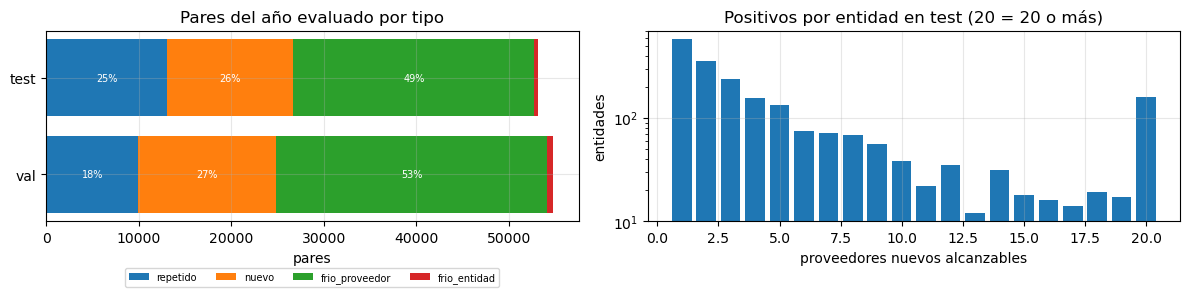

,entidades,mediana,pct_1_positivo,pct_10_o_mas,max
0,2112,3.0,27.5,18.0,120


In [7]:
TIPOS = ["repetido", "nuevo", "frio_proveedor", "frio_entidad"]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
comp = alcance.set_index("particion")[TIPOS]
izq = np.zeros(len(comp))
for t in TIPOS:
    ax[0].barh(comp.index, comp[t], left=izq, label=t)
    for j, (x, v) in enumerate(zip(izq, comp[t])):
        if v / comp.sum(1).iloc[j] > .05:
            ax[0].text(x + v / 2, j, f"{100 * v / comp.sum(1).iloc[j]:.0f}%", ha="center", va="center", fontsize=7, color="white")
    izq += comp[t].to_numpy()
ax[0].set_title("Pares del año evaluado por tipo"); ax[0].set_xlabel("pares")
ax[0].legend(fontsize=7, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.22))
_, _, pos_t = cargar_particion("test")
n_pos_e = pd.Series({e: len(v) for e, v in pos_t.items()})
v = n_pos_e.clip(upper=20).value_counts().sort_index()
ax[1].bar(v.index, v.values); ax[1].set_yscale("log")
ax[1].set_title("Positivos por entidad en test (20 = 20 o más)"); ax[1].set_xlabel("proveedores nuevos alcanzables"); ax[1].set_ylabel("entidades")
mostrar_fig("alcance")
positivos = pd.DataFrame([{"entidades": len(n_pos_e), "mediana": n_pos_e.median(), "pct_1_positivo": round(100 * (n_pos_e == 1).mean(), 1),
                           "pct_10_o_mas": round(100 * (n_pos_e >= 10).mean(), 1), "max": int(n_pos_e.max())}])
positivos

- **Solo 1 de cada 4 pares del año evaluado es un positivo** (`nuevo`): 26% en test y 27% en validación

- El bloque más grande es `frio_proveedor` (49-53%): proveedores que nunca habían ganado

- **Positivos por entidad:** mediana de 3; el 27.5% de las entidades tiene uno solo y el 18% tiene 10 o más

- Con 3 positivos y una lista de 10, la precision@10 máxima de una entidad típica es 0.3

---
### **3. Señal implícita**

Candidatas: `binaria` (1 si hubo adjudicación), `n_adj` (log1p del n.º de adjudicaciones) y `log_monto` (log1p del monto)

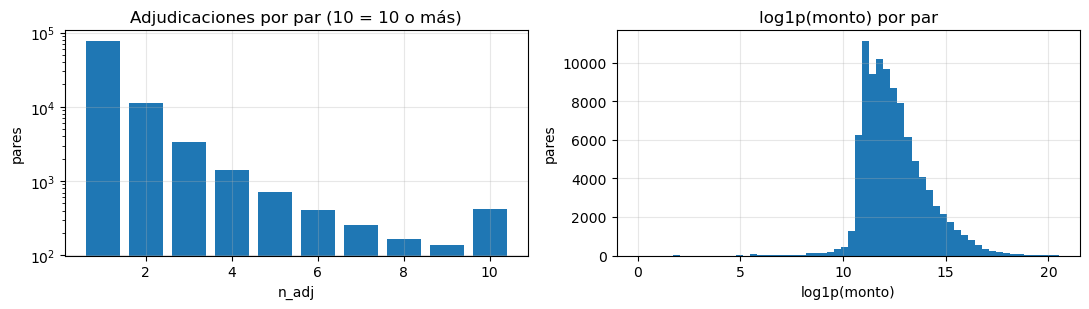

,pct_n_adj_1,p99_n_adj,pct_monto_nulo,log_monto_p25,log_monto_p75
0,81.2,7.0,0.0,11.4,13.3


In [8]:
tr, _, _ = cargar_particion("test")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
v = tr.n_adj.clip(upper=10).value_counts().sort_index()
ax[0].bar(v.index, v.values); ax[0].set_yscale("log")
ax[0].set_title("Adjudicaciones por par (10 = 10 o más)"); ax[0].set_xlabel("n_adj"); ax[0].set_ylabel("pares")
ax[1].hist(tr.senal_log_monto[tr.senal_log_monto > 0], bins=60)
ax[1].set_title("log1p(monto) por par"); ax[1].set_xlabel("log1p(monto)"); ax[1].set_ylabel("pares")
mostrar_fig("senal")
senal = pd.DataFrame([{"pct_n_adj_1": round(100 * (tr.n_adj == 1).mean(), 1),
                       "p99_n_adj": tr.n_adj.quantile(.99), "pct_monto_nulo": round(100 * (tr.senal_log_monto == 0).mean(), 1),
                       "log_monto_p25": round(tr.senal_log_monto.quantile(.25), 1), "log_monto_p75": round(tr.senal_log_monto.quantile(.75), 1)}])
senal

- **81.2% de los pares tiene una sola adjudicación**: `n_adj` casi no distingue intensidades

- `log_monto` es más variable, pero mezcla tamaño de obra con preferencia

---
### **4. Filtro `MIN_ENTIDADES`**

- Un proveedor con una sola entidad solo puede recomendarse a otra vía entidades parecidas a esa

- Umbrales: tamaño del catálogo, % de positivos que siguen siendo alcanzables y NDCG de un user-user de sonda

In [9]:
cfg = {"n_entidades": n_e, "n_proveedores": n_p}
guardar_config(cfg)

filtro = []
for p in PARTICIONES:
    tr, ev, pos = cargar_particion(p)
    X = matriz(tr, "binaria", (n_e, n_p))
    grado = np.asarray(X.sum(0)).ravel()
    punt = puntaje_usuario(X, K_SONDA)
    es_cons = idx_p.select("proveedor_idx", F.col("proveedor_key").startswith("CONS:").alias("c")).toPandas().sort_values("proveedor_idx").c.to_numpy()
    for t in RANGO_MIN_ENT:
        cat = grado >= t
        recs = top_k(punt, np.array(sorted(pos)), (X > 0).tocsr(), cat, k=K_EVAL)
        n_pos = sum(len(v) for v in pos.values())
        alc = sum(cat[list(v)].sum() for v in pos.values())
        filtro.append({"particion": p, "min_entidades": t, "catalogo": int(cat.sum()), "pct_pos_alcanzables": round(100 * alc / n_pos, 1),
                       "pct_consorcios": round(100 * es_cons[cat].mean(), 1), **evaluar(recs, pos, cat.sum())})
filtro = pd.DataFrame(filtro)
filtro

,particion,min_entidades,catalogo,pct_pos_alcanzables,pct_consorcios,precision@10,recall@10,ndcg@10,hit@10,cobertura
0,val,1,33832,100.0,36.2,0.0561,0.0992,0.0998,0.3658,0.1103
1,val,2,5474,73.6,0.0,0.0584,0.1113,0.1060,0.3841,0.4235
2,val,3,2794,58.4,0.0,0.0577,0.1065,0.1038,0.3777,0.6138
3,val,5,1191,40.9,0.0,0.0577,0.1075,0.1043,0.3767,0.8371
4,test,1,61141,100.0,44.4,0.0448,0.1052,0.0979,0.3338,0.0538
5,test,2,9653,75.3,0.0,0.0454,0.1071,0.0984,0.3385,0.2518
6,test,3,5267,61.0,0.0,0.0453,0.1065,0.0982,0.3371,0.3816
7,test,5,2380,44.6,0.0,0.0447,0.1028,0.0959,0.3314,0.5987


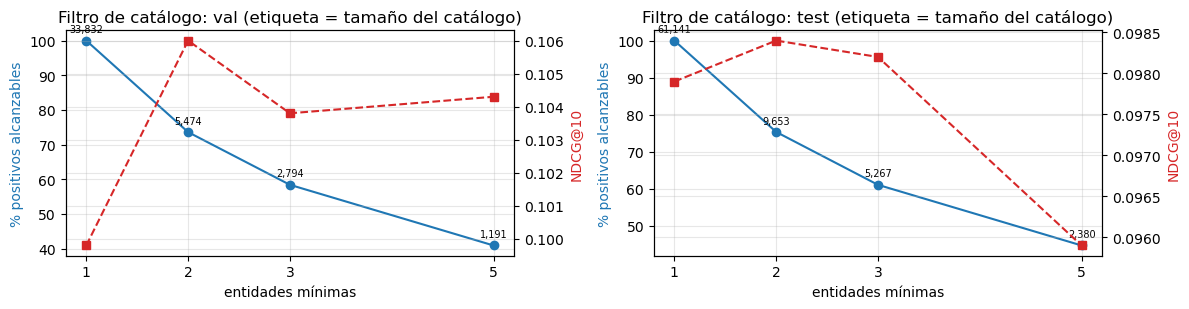

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
for i, p in enumerate(PARTICIONES):
    f = filtro[filtro.particion == p]
    ax[i].plot(f.min_entidades, f.pct_pos_alcanzables, "o-", color="tab:blue")
    ax[i].set_ylabel("% positivos alcanzables", color="tab:blue"); ax[i].set_xlabel("entidades mínimas"); ax[i].set_xticks(RANGO_MIN_ENT)
    a2 = ax[i].twinx()
    a2.plot(f.min_entidades, f["ndcg@10"], "s--", color="tab:red"); a2.set_ylabel("NDCG@10", color="tab:red")
    for x, n in zip(f.min_entidades, f.catalogo):
        ax[i].annotate(f"{n:,}", (x, f.pct_pos_alcanzables[f.min_entidades == x].iloc[0]), textcoords="offset points", xytext=(0, 6),
                       ha="center", fontsize=7)
    ax[i].set_title(f"Filtro de catálogo: {p} (etiqueta = tamaño del catálogo)")
mostrar_fig("filtro_catalogo")

- **Con 1 entidad:** catálogo de 61,141 proveedores en test

- **Con 2 entidades:** 9,653 proveedores (6× menos); conserva el **75.3% de los positivos**

- El NDCG es **máximo con 2** en validación (0.106) y en test

- Se fija `MIN_ENTIDADES = 2`; los positivos fuera del catálogo siguen en el denominador del recall

In [11]:
cfg["min_entidades"] = MIN_ENTIDADES
guardar_config(cfg)

---
### **5. Líneas base**

- **Popularidad global:** proveedores con más entidades distintas en entrenamiento

- **Popularidad regional:** lo mismo, contando solo proveedores de la región de la entidad

In [12]:
ent = (idx_e.join(leer(final_dir, "entidades").select("entidad_key", "nombre", "region"), "entidad_key", "left")
            .toPandas().sort_values("entidad_idx").reset_index(drop=True))
prov = (idx_p.join(leer(final_dir, "proveedores").select("proveedor_key", "nombre", "tipo"), "proveedor_key", "left")
             .toPandas().sort_values("proveedor_idx").reset_index(drop=True))
ent.to_parquet(datos_dir / "entidades", index=False)
prov.to_parquet(datos_dir / "proveedores", index=False)
region = ent.region.fillna("SIN").astype("category")
R = sp.csr_matrix((np.ones(n_e), (region.cat.codes, np.arange(n_e))), shape=(len(region.cat.categories), n_e))

def popularidad(X):
    g = np.asarray((X > 0).sum(0)).ravel().astype(np.float32)
    return lambda idx: np.tile(g, (len(idx), 1))

def regional(X):
    g = np.asarray((X > 0).sum(0)).ravel().astype(np.float32)
    G = (R @ (X > 0).astype(np.float32)).toarray()
    return lambda idx: G[region.cat.codes.to_numpy()[idx]] + g / (g.max() + 1)

base = []
for p in PARTICIONES:
    c = contexto(p)
    for nombre, f in {"popularidad": popularidad, "regional": regional}.items():
        recs = top_k(f(c["X"]), c["entidades"], c["vistos"], c["catalogo"])
        guardar_recs(recs, f"{nombre}_{p}")
        base.append({"particion": p, "modelo": nombre, **evaluar(recs, c["pos"], c["catalogo"].sum())})
base = pd.DataFrame(base)
base

,particion,modelo,precision@10,recall@10,ndcg@10,hit@10,cobertura
0,val,popularidad,0.0206,0.0305,0.0313,0.1676,0.0029
1,val,regional,0.0516,0.1358,0.1118,0.3811,0.0605
2,test,popularidad,0.0157,0.0307,0.0281,0.1378,0.0019
3,test,regional,0.0358,0.1008,0.0807,0.2860,0.0400


- **Popularidad global:** NDCG@10 de 0.028 en test; recomienda los mismos 18 proveedores a todos

- **Popularidad regional** es fuerte: **0.081 en test** (0.112 en validación)

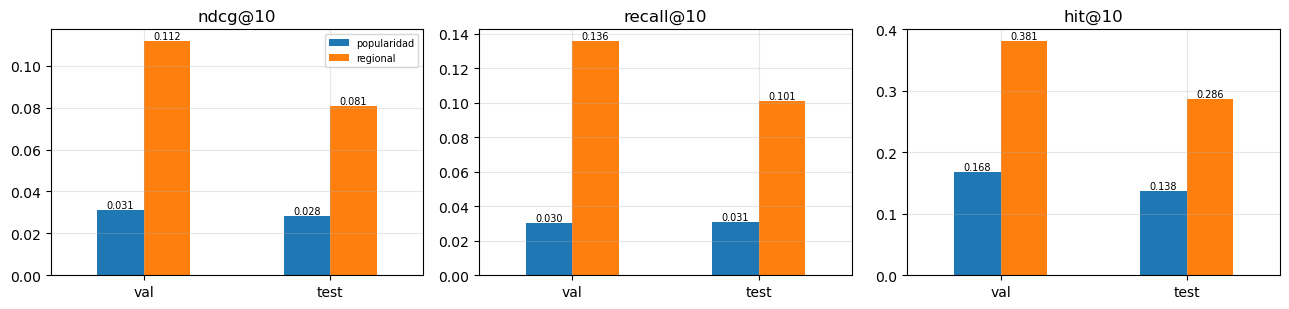

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for i, met in enumerate(["ndcg@10", "recall@10", "hit@10"]):
    t = base.pivot(index="particion", columns="modelo", values=met).loc[list(PARTICIONES)]
    t.plot.bar(ax=ax[i], rot=0, legend=(i == 0))
    for cont in ax[i].containers:
        ax[i].bar_label(cont, fmt="%.3f", fontsize=7)
    ax[i].set_title(met); ax[i].set_xlabel("")
ax[0].legend(fontsize=7)
mostrar_fig("lineas_base")

- La **regional triplica** a la global en NDCG y recall, en ambas particiones

- La global acierta algo en el 14% de las entidades; la regional, en el 29%

- Las dos bajan de validación a test: con dos años de historia hay más pares vistos que excluir

---
### **6. Escritura de datos**

- `temp/datos/<particion>_train`: pares de entrenamiento con `n_adj`, `monto` y `senal_log_monto`

- `temp/datos/<particion>_eval`: pares del año evaluado con su `tipo`

- `temp/datos/entidades`, `proveedores`: índice, clave, nombre y región o tipo

- `temp/datos/recs_<modelo>_<particion>`: top-`N_CAND` de cada línea base

- `temp/datos/config.json`: tamaños y `min_entidades`

#### a. Verificación

In [14]:
for p in PARTICIONES:
    tr, ev, pos = cargar_particion(p)
    vistos = set(zip(tr.entidad_idx, tr.proveedor_idx))
    assert not any((e, x) in vistos for e, v in pos.items() for x in v), p
    for m in ["popularidad", "regional"]:
        r = leer_recs(f"{m}_{p}")
        assert not any((e, x) in vistos for e, x in zip(r.entidad_idx, r.proveedor_idx)), (m, p)
        assert r.groupby("entidad_idx").size().max() <= N_CAND and set(r.entidad_idx) == set(pos), (m, p)
    print(f"{p}: {len(tr):,} pares de entrenamiento | {len(pos):,} entidades a evaluar | OK")

val: 51,185 pares de entrenamiento | 2,023 entidades a evaluar | OK


test: 96,022 pares de entrenamiento | 2,112 entidades a evaluar | OK


---
### **7. Escritura de resultados**

In [15]:
escritos = guardar_tablas({"alcance": alcance, "positivos_por_entidad": positivos, "senal": senal, "filtro_catalogo": filtro, "lineas_base": base})

Escrito en 03_Recomend/temp/a_preparacion/: alcance, positivos_por_entidad, senal, filtro_catalogo, lineas_base


#### a. Verificación

In [16]:
verificar_salidas(escritos)

OK: 5 tablas (parquet + json) | 4 figuras: alcance, filtro_catalogo, lineas_base, senal


---
### **8. Cerrar sesión**

In [17]:
spark.stop()